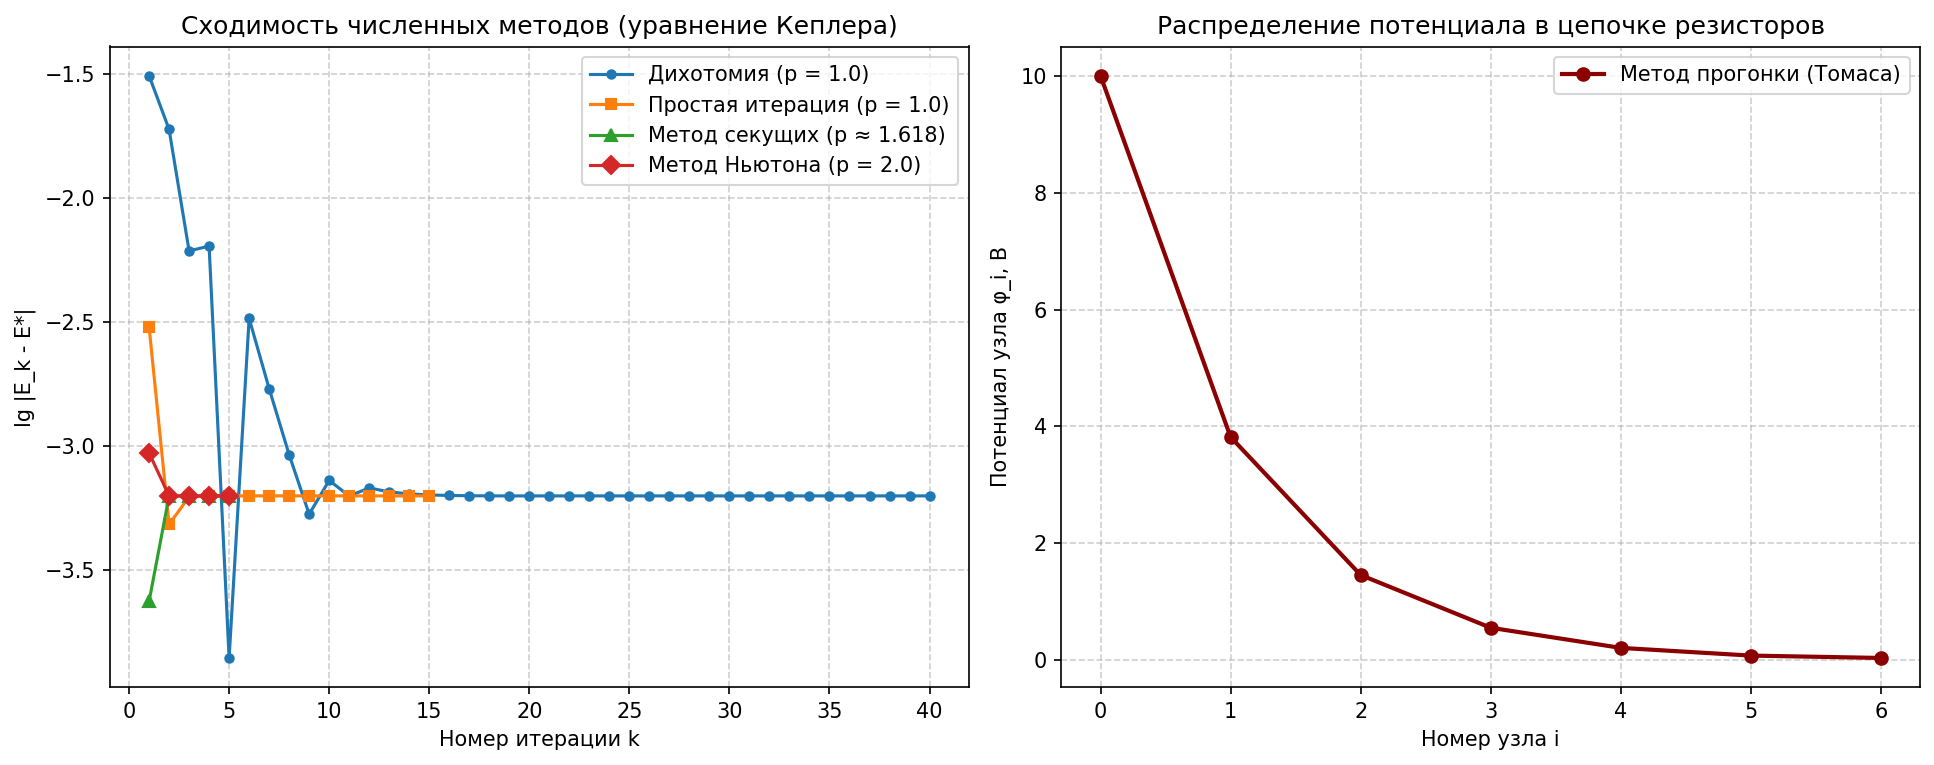

In [1]:
import numpy as np
import matplotlib.pyplot as plt

e = 0.0934
M = np.pi / 3.0
E_exact = 1.13111044955359

def f(E):
    return E - e * np.sin(E) - M

def df(E):
    return 1.0 - e * np.cos(E)

def bisection_errors(a, b, max_iter=40):
    errs = []
    for _ in range(max_iter):
        mid = 0.5 * (a + b)
        errs.append(max(abs(mid - E_exact), 1e-16))
        if f(a) * f(mid) < 0:
            b = mid
        else:
            a = mid
    return errs

def fixed_point_errors(x0, max_iter=15):
    errs = []
    x = x0
    for _ in range(max_iter):
        x = M + e * np.sin(x)
        errs.append(max(abs(x - E_exact), 1e-16))
    return errs

def secant_errors(x0, x1, max_iter=7):
    errs = []
    for _ in range(max_iter):
        f0, f1 = f(x0), f(x1)
        if abs(f1 - f0) < 1e-16:
            break
        x2 = x1 - f1 * (x1 - x0) / (f1 - f0)
        errs.append(max(abs(x2 - E_exact), 1e-16))
        x0, x1 = x1, x2
    return errs

def newton_errors(x0, max_iter=5):
    errs = []
    x = x0
    for _ in range(max_iter):
        x = x - f(x) / df(x)
        errs.append(max(abs(x - E_exact), 1e-16))
    return errs

err_bis = bisection_errors(1.0, 1.2)
err_fp = fixed_point_errors(M)
err_sec = secant_errors(1.0, 1.2)
err_newt = newton_errors(M)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)

ax1.plot(range(1, len(err_bis) + 1), np.log10(err_bis), 'o-', label='Дихотомия (p = 1.0)', markersize=4)
ax1.plot(range(1, len(err_fp) + 1), np.log10(err_fp), 's-', label='Простая итерация (p = 1.0)', markersize=5)
ax1.plot(range(1, len(err_sec) + 1), np.log10(err_sec), '^-', label='Метод секущих (p ≈ 1.618)', markersize=6)
ax1.plot(range(1, len(err_newt) + 1), np.log10(err_newt), 'D-', label='Метод Ньютона (p = 2.0)', markersize=6)

ax1.set_xlabel('Номер итерации k')
ax1.set_ylabel('lg |E_k - E*|')
ax1.set_title('Сходимость численных методов (уравнение Кеплера)')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

nodes = np.arange(0, 7)
potentials = np.array([10.0, 3.81966011, 1.45898034, 0.55728090, 0.21286236, 0.08130619, 0.04065310])

ax2.plot(nodes, potentials, 'o-', color='darkred', linewidth=2, markersize=6, label='Метод прогонки (Томаса)')
ax2.set_xlabel('Номер узла i')
ax2.set_ylabel('Потенциал узла φ_i, В')
ax2.set_title('Распределение потенциала в цепочке резисторов')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('sro8_convergence_and_potentials.png')
plt.show()